# PHA Dataset: EDA and Data Cleaning

Run the cells from top to bottom. This notebook loads the source CSV with Pandas, explores its data, visualizes selected features, cleans records, and saves the result in the `Data` folder.

## 1. Import libraries and locate the files

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Works when Jupyter starts in either the project folder or Notebook folder.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "Data" / "pha_dataset.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "Data" / "pha_dataset.csv"
CLEAN_PATH = PROJECT_ROOT / "Data" / "pha_dataset_cleaned.csv"
print("Source:", DATA_PATH)
print("Cleaned output:", CLEAN_PATH)

## 2. Load the CSV with Pandas

In [ ]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(df.head())

## 3. Inspect columns, data types, and distributions

In [ ]:
df.info()
display(df.describe(include="all").T)

## 4. Check missing values and duplicate rows

In [4]:
missing_counts = df.isna().sum().sort_values(ascending=False)
display(missing_counts[missing_counts > 0].to_frame("missing_count"))
print(f"Exact duplicate rows: {df.duplicated().sum():,}")

,missing_count
prefix,958506
name,936460
albedo,823421
diameter_sigma,822443
diameter,822315
sigma_per,19926
sigma_ad,19926
sigma_om,19922
sigma_ma,19922
sigma_q,19922


Exact duplicate rows: 0


## 5. Visualize selected numeric features

The source file is large, so plots use a random sample for faster rendering. The dataset itself is not sampled or changed by these plots.

In [5]:
plot_features = [column for column in ["H", "diameter", "albedo", "e", "a", "i", "moid", "rms"] if column in df.columns]
plot_df = df[plot_features].sample(n=min(20_000, len(df)), random_state=42)

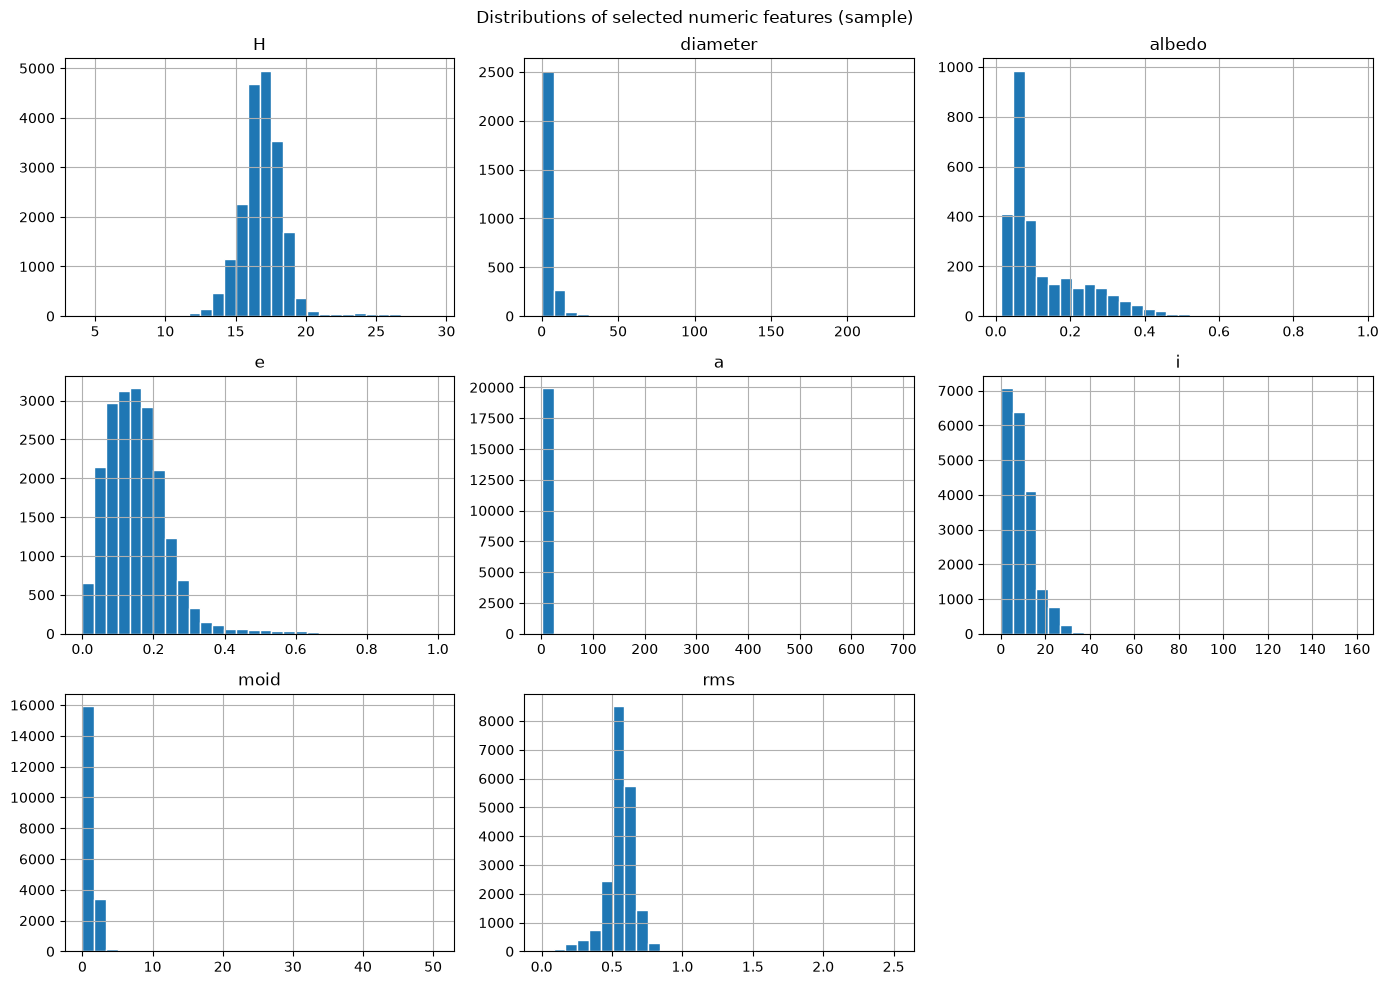

In [6]:
plot_df.hist(figsize=(14, 10), bins=30, layout=(-1, 3), edgecolor="white")
plt.suptitle("Distributions of selected numeric features (sample)")
plt.tight_layout()
plt.show()

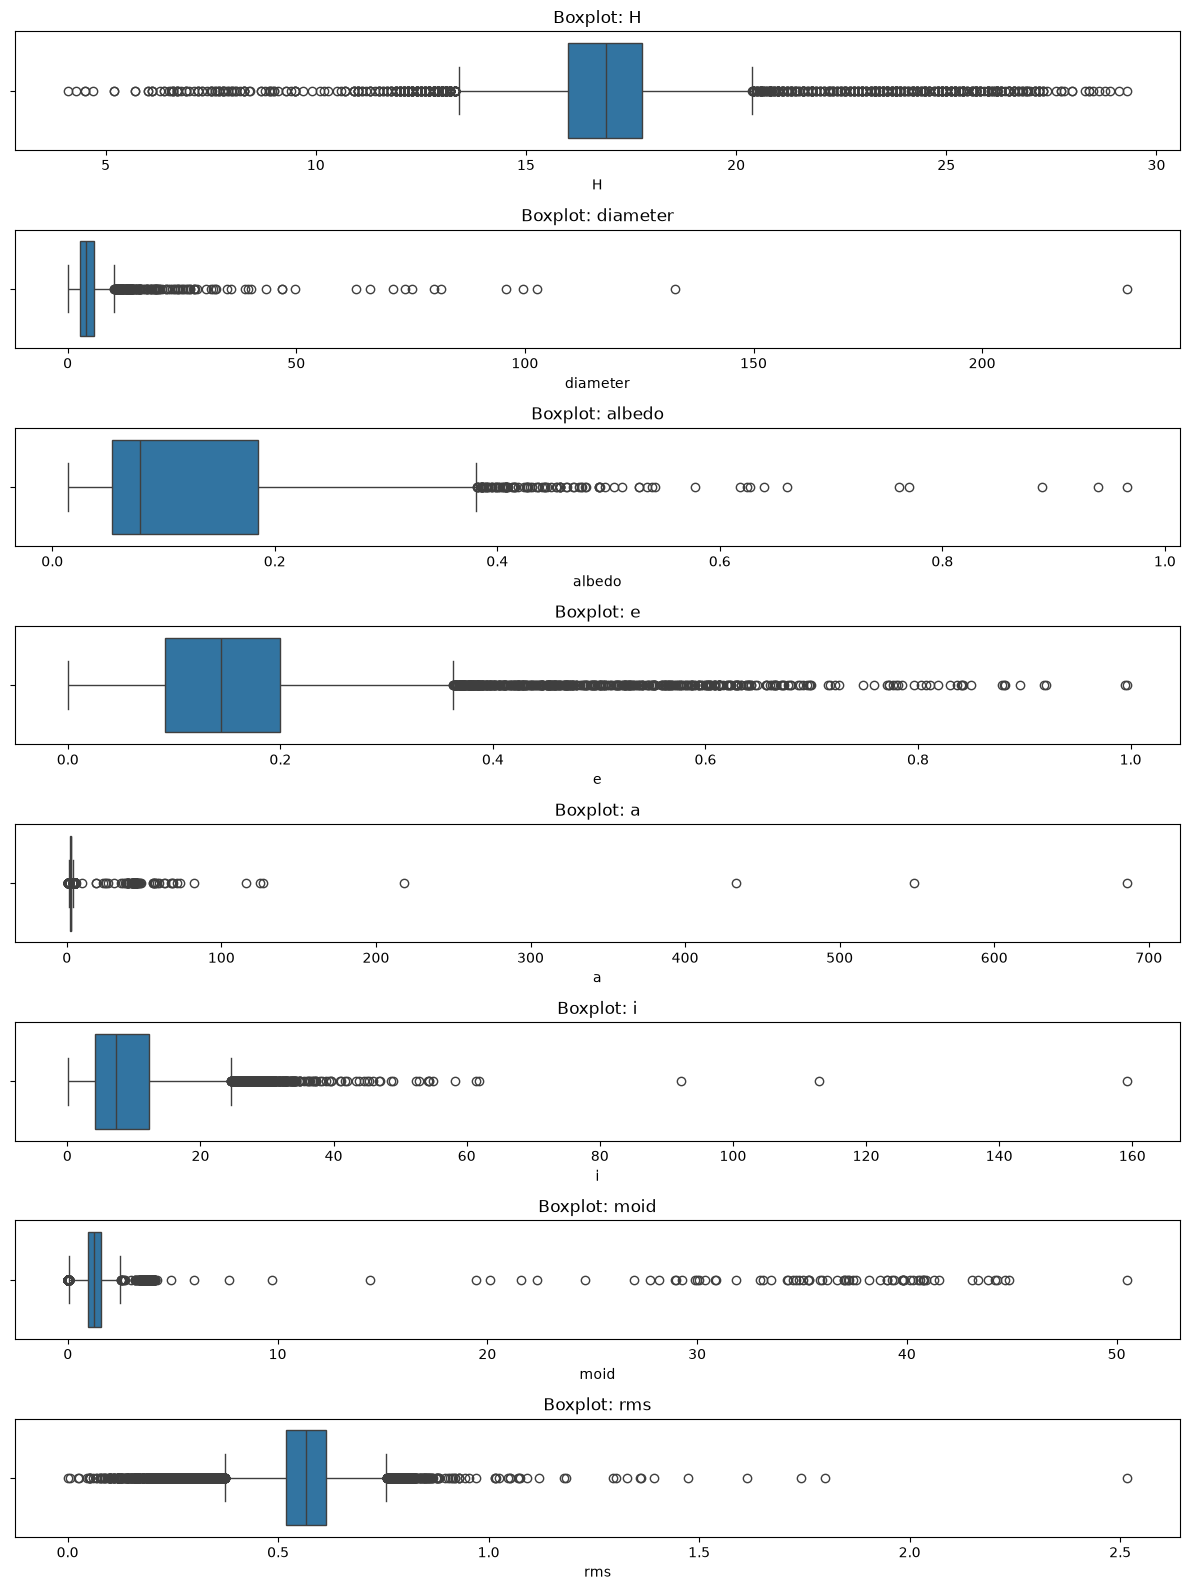

In [7]:
fig, axes = plt.subplots(len(plot_features), 1, figsize=(12, max(3, 2 * len(plot_features))))
if len(plot_features) == 1:
    axes = [axes]
for ax, column in zip(axes, plot_features):
    sns.boxplot(x=plot_df[column], ax=ax)
    ax.set_title(f"Boxplot: {column}")
plt.tight_layout()
plt.show()

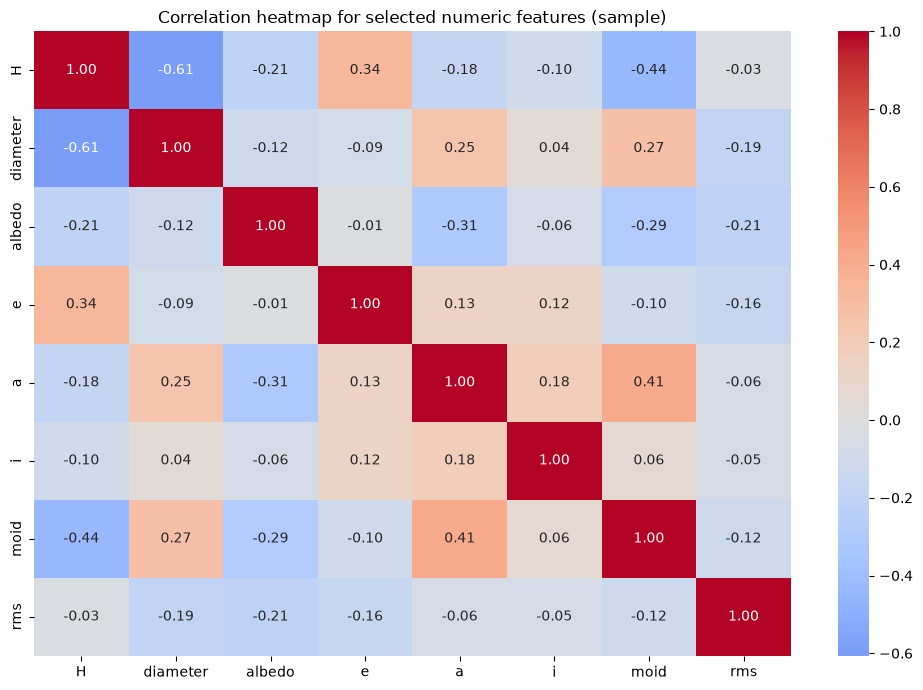

In [10]:
corr_features = [column for column in ["H", "diameter", "albedo", "e", "a", "i", "moid", "moid_Id", "rms"] if column in df.columns]
plt.figure(figsize=(10, 7))
sns.heatmap(plot_df[corr_features].corr(numeric_only=True), annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation heatmap for selected numeric features (sample)")
plt.tight_layout()
plt.show()

## 6. Clean text and remove duplicate/empty rows

Text fields are trimmed; the `neo` and `pha` flags are made uppercase. Other text categories retain their original case to avoid changing names and class labels.

In [11]:
cleaned = df.copy()
text_columns = cleaned.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    cleaned[column] = cleaned[column].str.strip().replace("", pd.NA)

for column in ["neo", "pha"]:
    if column in cleaned.columns:
        cleaned[column] = cleaned[column].str.upper()

rows_before = len(cleaned)
cleaned = cleaned.dropna(how="all").drop_duplicates().copy()
print(f"Removed {rows_before - len(cleaned):,} fully empty or duplicate rows.")
print(f"Shape after removing rows: {cleaned.shape[0]:,} rows x {cleaned.shape[1]} columns")

Removed 0 fully empty or duplicate rows.
Shape after removing rows: 958,524 rows x 45 columns


## 7. Handle missing values

Impute numeric measurements with their median and non-identifier categorical fields with their most common value. Missing identifiers and names are left missing rather than inventing identity values.

In [12]:
identifier_columns = {"id", "spkid", "pdes", "name", "full_name", "prefix", "orbit_id"}

for column in cleaned.select_dtypes(include="number").columns:
    if column not in identifier_columns and cleaned[column].isna().any():
        median_value = cleaned[column].median()
        if pd.notna(median_value):
            cleaned[column] = cleaned[column].fillna(median_value)

for column in cleaned.select_dtypes(include=["object", "string", "category"]).columns:
    if column not in identifier_columns and cleaned[column].isna().any():
        common_values = cleaned[column].mode(dropna=True)
        if not common_values.empty:
            cleaned[column] = cleaned[column].fillna(common_values.iloc[0])

remaining_missing = cleaned.isna().sum()
display(remaining_missing[remaining_missing > 0].to_frame("remaining_missing"))

,remaining_missing
name,936460
prefix,958506


## 8. Save the cleaned dataset

In [13]:
cleaned.to_csv(CLEAN_PATH, index=False)
print(f"Saved cleaned dataset to: {CLEAN_PATH}")
print(f"Final shape: {cleaned.shape[0]:,} rows x {cleaned.shape[1]} columns")

for column in ["neo", "pha"]:
    if column in cleaned.columns:
        print(f"\n{column} category counts:")
        display(cleaned[column].value_counts(dropna=False).to_frame("count"))

Saved cleaned dataset to: d:\Guvi\PDA\Data\pha_dataset_cleaned.csv
Final shape: 958,524 rows x 45 columns

neo category counts:


,count
neo,
N,935629
Y,22895



pha category counts:


,count
pha,
N,956458
Y,2066
